# Librerias

In [1]:
import sys
import os
import datetime
import shutil

# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join('../')))


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf



I0000 00:00:1793741155.799326   47573 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:

from src.Modelo_CNN import Vision_Model_Procesor

In [4]:
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Instancias para analisis

In [5]:
img_processor = Vision_Model_Procesor()

train_img_processor = Vision_Model_Procesor()
val_img_processor = Vision_Model_Procesor()
test_img_processor = Vision_Model_Procesor()

train_larva_img_processor = Vision_Model_Procesor()
val_larva_img_processor = Vision_Model_Procesor()
test_larva_img_processor = Vision_Model_Procesor()



# Revicion de imagenes

In [6]:
img_processor.train_data_folder = '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/train/'

img_processor.val_data_folder = '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/val/'

img_processor.categories = ['aegypti', 'albopictus', 'anopheles', 'culex']

img_processor.classify_img_by_folder()



Found 12000 files belonging to 4 classes.


I0000 00:00:1793741158.532830   47573 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4082 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


Found 4000 files belonging to 4 classes.
Train data: ['aegypti', 'albopictus', 'anopheles', 'culex']
Validation data: ['aegypti', 'albopictus', 'anopheles', 'culex']
Categorias de instancia: ['aegypti', 'albopictus', 'anopheles', 'culex']


In [7]:
img_processor.test_data_folder = '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/test/'


img_processor.set_df_img(
    '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/test/', 
    just_paths=True)

nuevo_df = img_processor.img_paths.data.melt(
    var_name='etiquetas', 
    value_name='rutas'
)

nuevo_df = nuevo_df.dropna(subset=['rutas']).reset_index(drop=True)

# se guarda el nuevo dataframe con las rutas y etiquetas en el orden correcto
img_processor.img_paths.data = nuevo_df[['rutas', 'etiquetas']]


img_processor.tab_data_processor.data = img_processor.img_paths.data

img_processor.tab_data_processor.data

Subcarpetas encontradas: ['aegypti', 'culex', 'anopheles', 'albopictus']


,rutas,etiquetas
0,/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...,aegypti
1,/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...,aegypti
2,/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...,aegypti
3,/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...,aegypti
4,/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...,aegypti
...,...,...
12631,/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...,albopictus
12632,/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...,albopictus
12633,/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...,albopictus
12634,/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...,albopictus


In [8]:
img_processor.img_path_x_label_col(0, 1, test = True, one_hot_category = False)

In [9]:
img_processor.train_data


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 550, 550, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [10]:
img_processor.val_data

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 550, 550, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [11]:
img_processor.test_data

{'tf_dataset': <_BatchDataset element_spec=(TensorSpec(shape=(None, 550, 550, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None))>,
 'pd_dataset':                                                    Rutas   Etiquetas
 0      /home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...     aegypti
 1      /home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...     aegypti
 2      /home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...     aegypti
 3      /home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...     aegypti
 4      /home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...     aegypti
 ...                                                  ...         ...
 12631  /home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...  albopictus
 12632  /home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...  albopictus
 12633  /home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...  albopictus
 12634  /home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA...  albopictus
 12635  /home/hadoop/CUC/IA_Aplicada/Proyecto_V

## Dimenciones originales de las imagenes

### Set de entrenamiento

In [12]:
img_processor.train_data_folder

'/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/train/'

In [14]:
img_processor.set_df_img(path = img_processor.train_data_folder)

img_processor.df_img

Subcarpetas encontradas: ['aegypti', 'culex', 'anopheles', 'albopictus']
Cantidad de archivos en aegypti: 3000
Cantidad de archivos en culex: 3000
Cantidad de archivos en anopheles: 3000
Cantidad de archivos en albopictus: 3000


{'aegypti': <src.Tabular_Data_Processor.TabularDataProcessor at 0x70e88e1bbbf0>,
 'culex': <src.Tabular_Data_Processor.TabularDataProcessor at 0x70e8b20c6660>,
 'anopheles': <src.Tabular_Data_Processor.TabularDataProcessor at 0x70e8a01c0260>,
 'albopictus': <src.Tabular_Data_Processor.TabularDataProcessor at 0x70e814607fe0>}

In [15]:
img_processor.df_img['aegypti'].data.describe()

,Alto,Ancho,Canal
count,3000.000000,3000.000000,3000.0
mean,1948.338667,2254.786333,3.0
std,1901.857869,2723.426335,0.0
min,29.000000,28.000000,3.0
25%,437.750000,422.500000,3.0
50%,833.000000,798.000000,3.0
75%,4608.000000,3456.000000,3.0
max,4744.000000,8432.000000,3.0


In [ ]:
img_processor.df_img['albopictus'].data.describe()

,Alto,Ancho,Canal
count,7482.000000,7482.000000,7482.0
mean,572.751270,578.937584,3.0
std,361.700116,368.599629,0.0
min,32.000000,34.000000,3.0
25%,287.000000,289.000000,3.0
50%,480.000000,485.000000,3.0
75%,778.750000,781.750000,3.0
max,2047.000000,2047.000000,3.0


In [ ]:
img_processor.df_img['anopheles'].data.describe()

,Alto,Ancho,Canal
count,2586.000000,2586.000000,2586.0
mean,892.982212,830.839134,3.0
std,401.549677,375.616334,0.0
min,42.000000,52.000000,3.0
25%,583.250000,540.000000,3.0
50%,866.500000,807.000000,3.0
75%,1168.000000,1071.750000,3.0
max,2035.000000,2041.000000,3.0


In [ ]:
img_processor.df_img['culex'].data.describe()

,Alto,Ancho,Canal
count,8303.000000,8303.000000,8303.0
mean,811.063953,766.847766,3.0
std,400.938193,386.720802,0.0
min,36.000000,29.000000,3.0
25%,498.000000,463.000000,3.0
50%,753.000000,709.000000,3.0
75%,1084.000000,1023.000000,3.0
max,2047.000000,2047.000000,3.0


## Vista de data preparada

Clases detectadas: ['aegypti', 'albopictus', 'anopheles', 'culex']


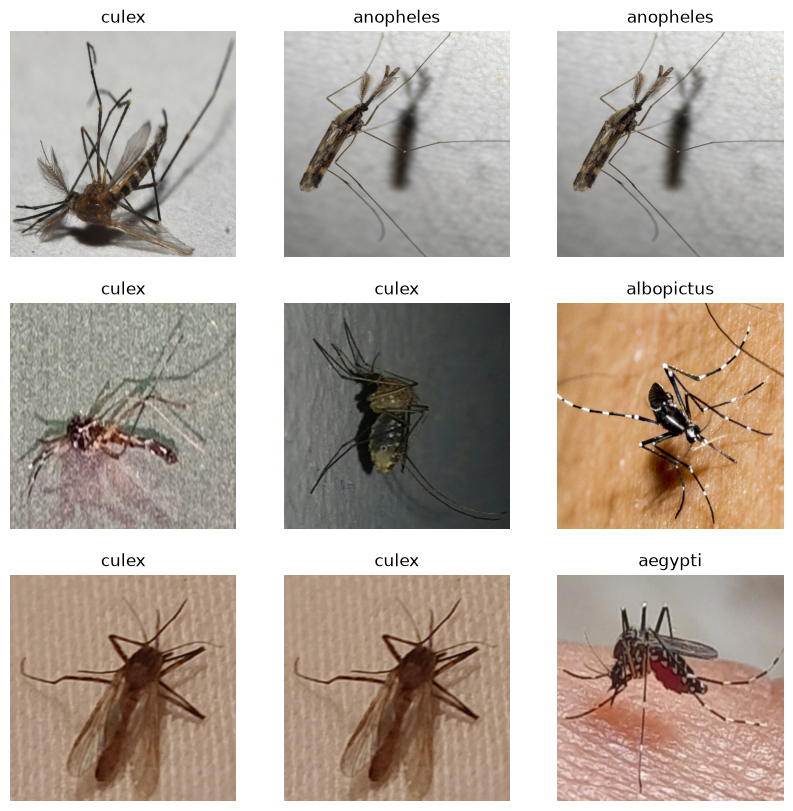

In [19]:
img_processor.show_sample_image_x_label('train') # Vista de datos para entrenamiento

Clases detectadas: ['aegypti', 'albopictus', 'anopheles', 'culex']


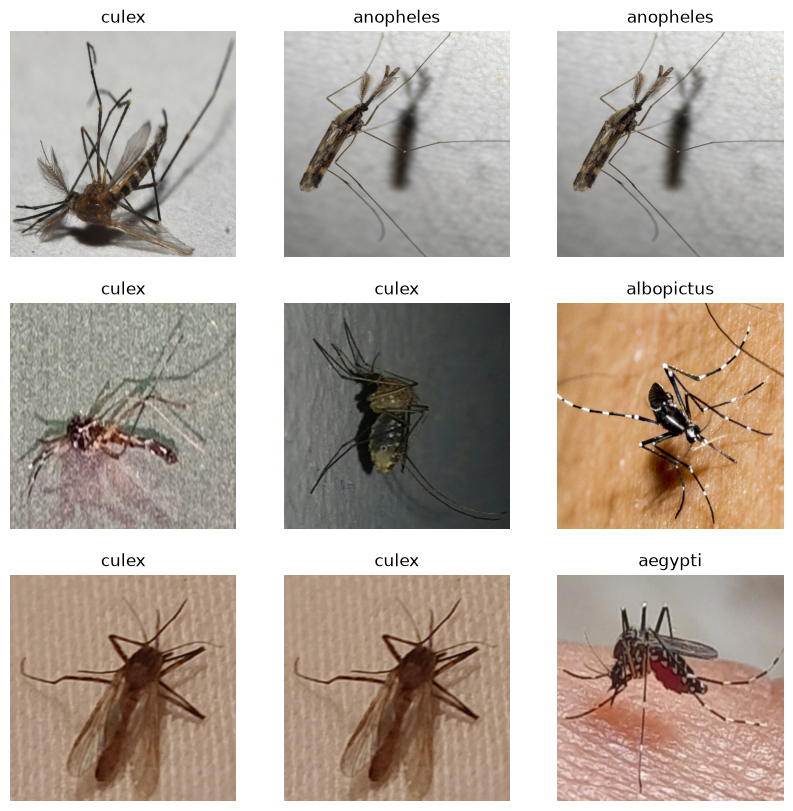

In [ ]:
img_processor.show_sample_image_x_label('val') # Vista de datos para entrenamiento

Clases detectadas: ['aegypti', 'albopictus', 'anopheles', 'culex']


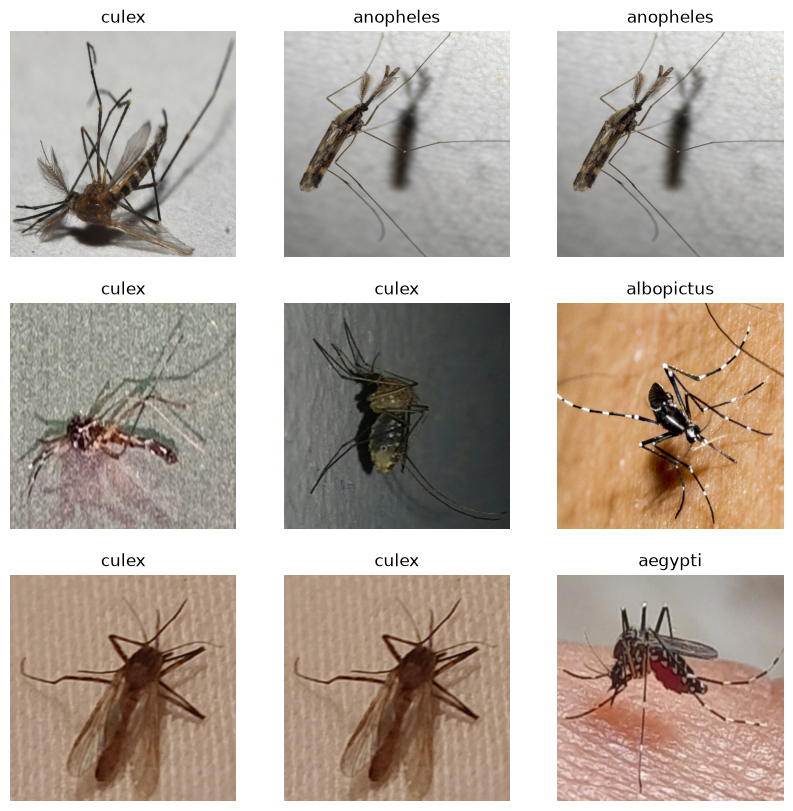

In [ ]:
img_processor.show_sample_image_x_label('test') # Vista de datos para entrenamiento